# Paso 5 — Grafo epileptogénico, propagación y grafo dinámico

Notebook reproducible estilo Google Colab para estudiar la interacción entre

\[
\boxed{\text{heterogeneidad de excitabilidad}+
\text{estructura de red}+
\text{dinámica de los Epileptores}+
\text{propagación}}
\]

El flujo principal implementado es

\[
A\rightarrow G\rightarrow X(t)\rightarrow T_i\rightarrow W(t)
\rightarrow I\rightarrow \text{reclutamiento}\rightarrow N\text{-scaling}.
\]

**Importante:** la construcción \(A=A(x_0)\) es una hipótesis de modelamiento artificial. No debe interpretarse como evidencia de que la conectividad cerebral real depende directamente de \(x_0\).

El notebook distingue resultados analíticos, numéricos, estadísticos y conjeturas.


## 0. Instalación y configuración de Colab

El notebook usa `numpy`, `scipy`, `networkx`, `pandas`, `matplotlib` y `seaborn`.

Las simulaciones grandes y los experimentos estadísticos se mantienen desactivados por defecto para que el notebook pueda ejecutarse de forma interactiva.


In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.integrate import solve_ivp
from scipy.stats import pearsonr, spearmanr
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import norm as sparse_norm

# Reproducibilidad y directorios
SEED = 42
rng = np.random.default_rng(SEED)

FIG_DIR = Path("figuras")
RES_DIR = Path("results")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 100)

print("Seed:", SEED)
print("NumPy:", np.__version__)


Seed: 42
NumPy: 2.1.3


# 1. Modelo matemático

Para \(i=0,\ldots,N-1\):

\[
\dot x_i=-x_i^3-2x_i^2+1-z_i+I_i,
\]

\[
\dot z_i=
\frac1{\tau_0}
\left[
h_i(x_i)-z_i-K\sum_jA_{ij}(x_j-x_i)
\right],
\]

con

\[
h_i(x)=x_{0,i}-3+
\frac{3}{1+\exp(-(x-0.5)/0.1)}.
\]

Inicialmente:

\[
\tau_0=2857,\qquad I_i=3.1.
\]

El valor \(x_0\approx2.91\) se usa únicamente como referencia para etiquetar la heterogeneidad; **no se asume como umbral universal**.


In [ ]:
# Parámetros del modelo
TAU0 = 2857.0
I_DEFAULT = 3.1
X0_REFERENCE = 2.91

def sigmoid_stable(u):
    """Sigmoide numéricamente estable."""
    u = np.asarray(u)
    out = np.empty_like(u, dtype=float)
    pos = u >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-u[pos]))
    eu = np.exp(u[~pos])
    out[~pos] = eu / (1.0 + eu)
    return out

def h_i(x, x0_i):
    """Función h_i(x) del modelo."""
    return x0_i - 3.0 + 3.0 * sigmoid_stable((np.asarray(x) - 0.5) / 0.1)

def generate_x0(N=10, seed=42):
    """Genera la heterogeneidad exactamente según las instrucciones del modelo."""
    if N < 2:
        raise ValueError("N debe ser >= 2.")
    local_rng = np.random.default_rng(seed)
    x0 = local_rng.normal(2.5, 0.5, N)
    x0[0] = 2.3
    x0[1] = 2.4
    if N > 2:
        x0[2:] = local_rng.uniform(2.9, 3.5, N - 2)
    return x0

N = 10
x0 = generate_x0(N, SEED)
I_vec = np.full(N, I_DEFAULT)

print("N =", N)
print("x0 =", x0)


N = 10
x0 = [2.3    2.4    3.1225 3.4561 3.2863 3.3937 3.166  3.0363 3.2328 2.9383]


# 2. Construcción del grafo

La definición solicitada es

\[
A_{ij}=
\begin{cases}
1,&x_{0,j}<x_{0,i}\text{ e }i\neq j,\\
0,&\text{en otro caso}.
\end{cases}
\]

Se conserva **exactamente** esta definición. No se transpone silenciosamente.


In [ ]:
def build_adjacency(x0):
    """Construye A_ij = 1 si x0_j < x0_i y i != j."""
    x0 = np.asarray(x0, dtype=float)
    A = ((x0[None, :] < x0[:, None]) & ~np.eye(len(x0), dtype=bool)).astype(int)
    return A

def build_graph(A):
    """Construye el DiGraph siguiendo literalmente nx.DiGraph(A)."""
    return nx.DiGraph(np.asarray(A))

A = build_adjacency(x0)
G = build_graph(A)

print("A =")
print(A)
print("\nAristas de nx.DiGraph(A):")
print(list(G.edges()))


A =
[[0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 1 0 1]
 [1 1 1 0 1 1 1 1 1 1]
 [1 1 1 0 0 0 1 1 1 1]
 [1 1 1 0 1 0 1 1 1 1]
 [1 1 1 0 0 0 0 1 0 1]
 [1 1 0 0 0 0 0 0 0 1]
 [1 1 1 0 0 0 1 1 0 1]
 [1 1 0 0 0 0 0 0 0 0]]

Aristas de nx.DiGraph(A):
[(1, 0), (2, 0), (2, 1), (2, 7), (2, 9), (3, 0), (3, 1), (3, 2), (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9), (4, 0), (4, 1), (4, 2), (4, 6), (4, 7), (4, 8), (4, 9), (5, 0), (5, 1), (5, 2), (5, 4), (5, 6), (5, 7), (5, 8), (5, 9), (6, 0), (6, 1), (6, 2), (6, 7), (6, 9), (7, 0), (7, 1), (7, 9), (8, 0), (8, 1), (8, 2), (8, 6), (8, 7), (8, 9), (9, 0), (9, 1)]


# 3. Verificación obligatoria de la convención de dirección

Para `nx.DiGraph(A)`, una entrada \(A_{ij}=1\) genera la arista

\[
i\rightarrow j.
\]

Sin embargo, en el término dinámico

\[
\sum_j A_{ij}(x_j-x_i),
\]

el estado \(x_j\) aparece en la ecuación de \(i\). Por tanto, **desde la interpretación dinámica**, \(j\) es quien influye sobre \(i\).

Así, la arista de NetworkX \(i\to j\) no coincide directamente con la flecha "influencia \(j\to i\)" asociada al término dinámico. Por eso se deben conservar y comparar ambas convenciones:

- `A`: definición original + representación literal en NetworkX.
- `A.T`: convención transpuesta, útil si se desea que una arista `j -> i` represente que \(j\) influye sobre \(i\).

No se cambia la definición original automáticamente.


In [ ]:
# Ejemplo pequeño obligatorio
x0_demo = np.array([2.3, 2.4, 3.1])
A_demo = build_adjacency(x0_demo)
G_demo = build_graph(A_demo)

print("x0_demo =", x0_demo)
print("\nA_demo =")
print(A_demo)

print("\nAristas de nx.DiGraph(A_demo):")
for u, v in G_demo.edges():
    print(f"{u} -> {v}   (NetworkX)")

print("\nInterpretación del término dinámico A_ij(x_j-x_i):")
for i in range(len(x0_demo)):
    js = np.where(A_demo[i] == 1)[0]
    print(f"Ecuación de i={i}: recibe términos desde j={list(js)}")

print("\nMatriz transpuesta A_demo.T =")
print(A_demo.T)


x0_demo = [2.3 2.4 3.1]

A_demo =
[[0 0 0]
 [1 0 0]
 [1 1 0]]

Aristas de nx.DiGraph(A_demo):
1 -> 0   (NetworkX)
2 -> 0   (NetworkX)
2 -> 1   (NetworkX)

Interpretación del término dinámico A_ij(x_j-x_i):
Ecuación de i=0: recibe términos desde j=[]
Ecuación de i=1: recibe términos desde j=[np.int64(0)]
Ecuación de i=2: recibe términos desde j=[np.int64(0), np.int64(1)]

Matriz transpuesta A_demo.T =
[[0 1 1]
 [0 0 1]
 [0 0 0]]


### Test conceptual de la dirección

Para \(x_0=(2.3,2.4,3.1)\):

- la región 2 tiene el mayor \(x_0\);
- \(A_{2,0}=A_{2,1}=1\);
- `nx.DiGraph(A)` dibuja \(2\to0\) y \(2\to1\);
- pero en la ecuación de la región 2 aparecen \(x_0\) y \(x_1\).

Por lo tanto, si las flechas se interpretan como **influencia dinámica**, la convención natural asociada al término es la transpuesta.

Esta distinción será evaluada experimentalmente más adelante.


# 4. Visualización del grafo estructural

Rojo: \(x_{0,i}<2.91\) (región etiquetada como epileptogénica bajo esta regla).

Azul: \(x_{0,i}\ge2.91\).

Esto es una **clasificación operativa para la simulación**, no una afirmación de que \(2.91\) sea un umbral fisiológico universal.


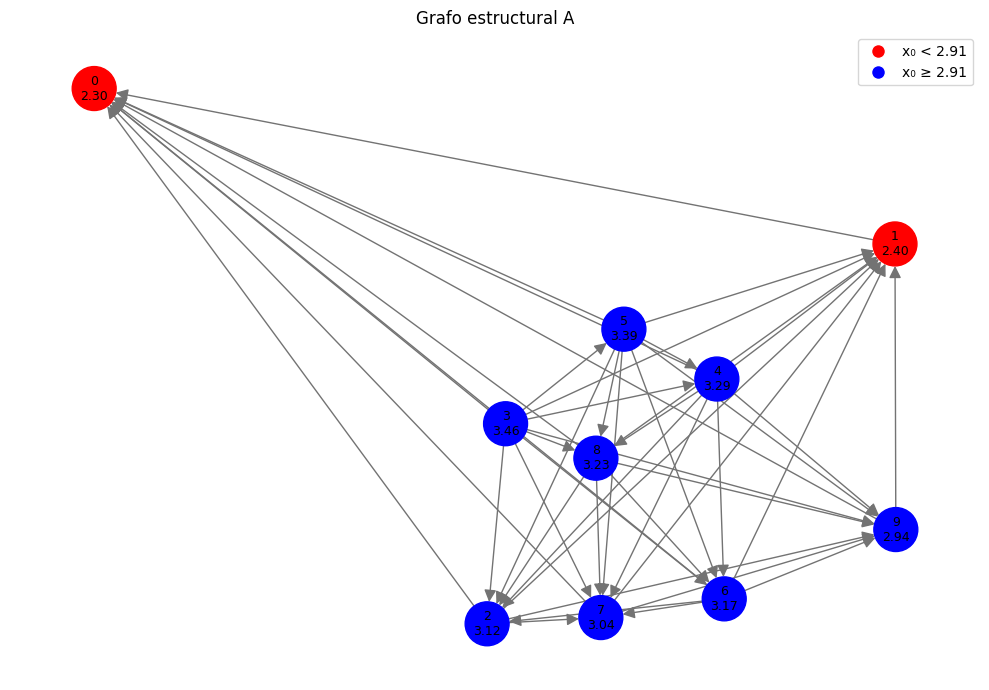

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Grafo estructural A'}>)

In [ ]:
def plot_structural_graph(A, x0, filename=FIG_DIR/"grafo.png", title=None):
    G = build_graph(A)
    pos = nx.spring_layout(G, seed=42)

    colors = ['red' if x < X0_REFERENCE else 'blue' for x in x0]
    labels = {i: f"{i}\n{x0[i]:.2f}" for i in range(len(x0))}

    fig, ax = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(
        G, pos=pos, ax=ax,
        node_color=colors,
        labels=labels,
        arrows=True,
        node_size=1000,
        arrowsize=18,
        edge_color="0.45",
        font_size=9
    )
    ax.set_title(title or "Grafo estructural A")
    ax.axis("off")

    from matplotlib.lines import Line2D
    legend = [
        Line2D([0], [0], marker='o', color='w', label='x₀ < 2.91',
               markerfacecolor='red', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='x₀ ≥ 2.91',
               markerfacecolor='blue', markersize=10)
    ]
    ax.legend(handles=legend, loc="best")
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    return fig, ax

plot_structural_graph(A, x0)


# 5. Métricas topológicas

Se calculan:

\[
d_i^{out},\qquad d_i^{in},\qquad C_B(i).
\]

La longitud media de caminos se calcula **solo cuando tiene sentido**. Para un grafo dirigido no fuertemente conexo no se fuerza `average_shortest_path_length`.


In [ ]:
def graph_metrics(G):
    metrics = pd.DataFrame(index=sorted(G.nodes()))
    metrics.index.name = "node"

    metrics["out_degree"] = pd.Series(dict(G.out_degree()))
    metrics["in_degree"] = pd.Series(dict(G.in_degree()))
    metrics["betweenness"] = pd.Series(nx.betweenness_centrality(G))
    metrics["clustering"] = pd.Series(nx.clustering(G))

    scc = list(nx.strongly_connected_components(G))
    metrics["scc_id"] = -1
    for k, comp in enumerate(scc):
        for node in comp:
            metrics.loc[node, "scc_id"] = k

    if nx.is_strongly_connected(G):
        metrics.attrs["average_shortest_path_length"] = nx.average_shortest_path_length(G)
    else:
        metrics.attrs["average_shortest_path_length"] = None

    return metrics

topology = graph_metrics(G)
display(topology)

if topology.attrs["average_shortest_path_length"] is None:
    print("El grafo no es fuertemente conexo: no se fuerza la longitud media dirigida.")
    print("Se reportan componentes fuertemente conexas y se puede estudiar el grafo subyacente no dirigido.")
else:
    print("Average shortest path length:", topology.attrs["average_shortest_path_length"])


,out_degree,in_degree,betweenness,clustering,scc_id
node,,,,,
0,0,9,0.0,0.5,0
1,1,8,0.0,0.5,1
2,4,5,0.0,0.5,4
3,9,0,0.0,0.5,9
4,7,2,0.0,0.5,7
5,8,1,0.0,0.5,8
6,5,4,0.0,0.5,5
7,3,6,0.0,0.5,3
8,6,3,0.0,0.5,6


El grafo no es fuertemente conexo: no se fuerza la longitud media dirigida.
Se reportan componentes fuertemente conexas y se puede estudiar el grafo subyacente no dirigido.


# 6. Dinámica de los Epileptores

El estado completo es

\[
X=(x_0,\ldots,x_{N-1},z_0,\ldots,z_{N-1}).
\]

La implementación permite cambiar \(A\), \(K\), \(I\), \(\tau_0\), y usar \(A^T\) sin modificar la definición original.


In [ ]:
def rhs(t, state, x0, A, K, tau0=TAU0, I=None):
    """RHS del sistema acoplado de N Epileptores."""
    x0 = np.asarray(x0, dtype=float)
    A = np.asarray(A, dtype=float)
    N = len(x0)

    x = state[:N]
    z = state[N:]

    if I is None:
        I = np.full(N, I_DEFAULT)
    I = np.asarray(I, dtype=float)

    coupling = np.sum(A * (x[None, :] - x[:, None]), axis=1)

    dx = -x**3 - 2*x**2 + 1.0 - z + I
    dz = (h_i(x, x0) - z - K * coupling) / tau0

    return np.concatenate([dx, dz])

def validate_rhs_matrix_form(x, A):
    """Verifica sum_j A_ij (x_j-x_i) mediante dos implementaciones."""
    x = np.asarray(x)
    A = np.asarray(A)
    direct = np.sum(A * (x[None, :] - x[:, None]), axis=1)
    matrix_form = A @ x - np.sum(A, axis=1) * x
    return direct, matrix_form


## 7. Integración numérica y convergencia

Se utiliza `solve_ivp`, comenzando con `DOP853`.

La configuración numérica no debe determinar las conclusiones. Por ello se incluye una comparación de tolerancias y `max_step`.


In [ ]:
def simulate(
    x0, A, K,
    x_init=None, z_init=None,
    T=30000.0,
    n_samples=5000,
    method="DOP853",
    rtol=1e-8,
    atol=1e-10,
    max_step=np.inf,
    I=None,
    tau0=TAU0
):
    """Simula el sistema y devuelve tiempos, x, z y el objeto solve_ivp."""
    x0 = np.asarray(x0, dtype=float)
    N = len(x0)

    if x_init is None:
        x_init = np.full(N, -1.0)
    if z_init is None:
        z_init = np.zeros(N)

    y0 = np.concatenate([x_init, z_init])
    t_eval = np.linspace(0.0, T, n_samples)

    sol = solve_ivp(
        rhs, (0.0, T), y0,
        args=(x0, A, K, tau0, I),
        method=method,
        t_eval=t_eval,
        rtol=rtol,
        atol=atol,
        max_step=max_step
    )

    if not sol.success:
        warnings.warn(sol.message)

    N = len(x0)
    x = sol.y[:N]
    z = sol.y[N:]

    return sol.t, x, z, sol

# Ejemplo corto para comprobar que el pipeline funciona.
t_test, x_test, z_test, sol_test = simulate(
    x0, A, K=0.0, T=500.0, n_samples=1000, max_step=50.0
)
print("success:", sol_test.success)
print("nfev:", sol_test.nfev)


success: True
nfev: 9968


In [ ]:
# Test 5: implementación directa vs forma matricial
x_random = rng.normal(size=N)
direct, matrix_form = validate_rhs_matrix_form(x_random, A)
assert np.allclose(direct, matrix_form), "Falló la equivalencia del término de acoplamiento."

# Test 4: A=0 desacopla las ecuaciones
zero_A = np.zeros_like(A)
state_random = rng.normal(size=2*N)
r0 = rhs(0.0, state_random, x0, zero_A, K=3.0)
r0_again = rhs(0.0, state_random, x0, zero_A, K=0.0)
assert np.allclose(r0, r0_again), "A=0 no desacopló correctamente el término de red."

# Test 1 y 2
assert np.all(np.diag(A) == 0), "A_ii debe ser 0."
for i in range(N):
    for j in range(N):
        expected = int(i != j and x0[j] < x0[i])
        assert A[i, j] == expected

print("Todos los tests algebraicos básicos pasaron.")


Todos los tests algebraicos básicos pasaron.


# 8. Condiciones iniciales

Se implementan los tres experimentos pedidos:

**A — homogéneas**

\[
x_i(0)=x_0^{init},\qquad z_i(0)=z_0^{init}.
\]

**B — pequeñas perturbaciones**

\[
x_i(0)=x^{init}+\epsilon_i,\qquad z_i(0)=z^{init}+\eta_i.
\]

**C — aleatorias**

Condiciones iniciales aleatorias dentro de una región configurable.


In [ ]:
def initial_conditions(N, experiment="A", seed=42,
                        x_init=-1.0, z_init=0.0,
                        perturbation_scale=1e-2):
    local_rng = np.random.default_rng(seed)

    if experiment == "A":
        x = np.full(N, x_init)
        z = np.full(N, z_init)

    elif experiment == "B":
        x = np.full(N, x_init) + local_rng.normal(0, perturbation_scale, N)
        z = np.full(N, z_init) + local_rng.normal(0, perturbation_scale, N)

    elif experiment == "C":
        x = local_rng.uniform(-2.0, 2.0, N)
        z = local_rng.uniform(-1.0, 1.0, N)

    else:
        raise ValueError("experiment debe ser A, B o C")

    return x, z

x_init_A, z_init_A = initial_conditions(N, "A", SEED)
x_init_B, z_init_B = initial_conditions(N, "B", SEED)
x_init_C, z_init_C = initial_conditions(N, "C", SEED)

print("A:", x_init_A[:3], z_init_A[:3])
print("B:", x_init_B[:3], z_init_B[:3])
print("C:", x_init_C[:3], z_init_C[:3])


A: [-1. -1. -1.] [0. 0. 0.]
B: [-0.997  -1.0104 -0.9925] [0.0088 0.0078 0.0007]
C: [ 1.0958 -0.2445  1.4344] [-0.2584  0.8535  0.2877]


# 9. Series temporales y actividad colectiva

Se definen

\[
m_N(t)=\frac1N\sum_i x_i(t),
\]

\[
m_{\rm epi}(t)=\frac{x_0(t)+x_1(t)}2,
\]

\[
m_{\rm sano}(t)=\frac1{N-2}\sum_{i=2}^{N-1}x_i(t).
\]

Las tres curvas permiten comparar la actividad de las regiones etiquetadas como epileptogénicas con las restantes.


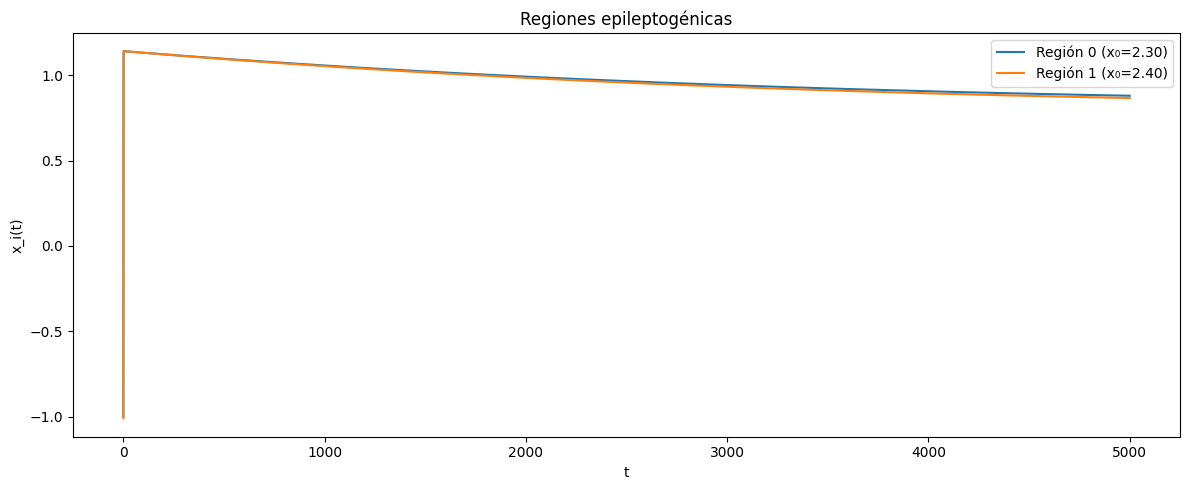

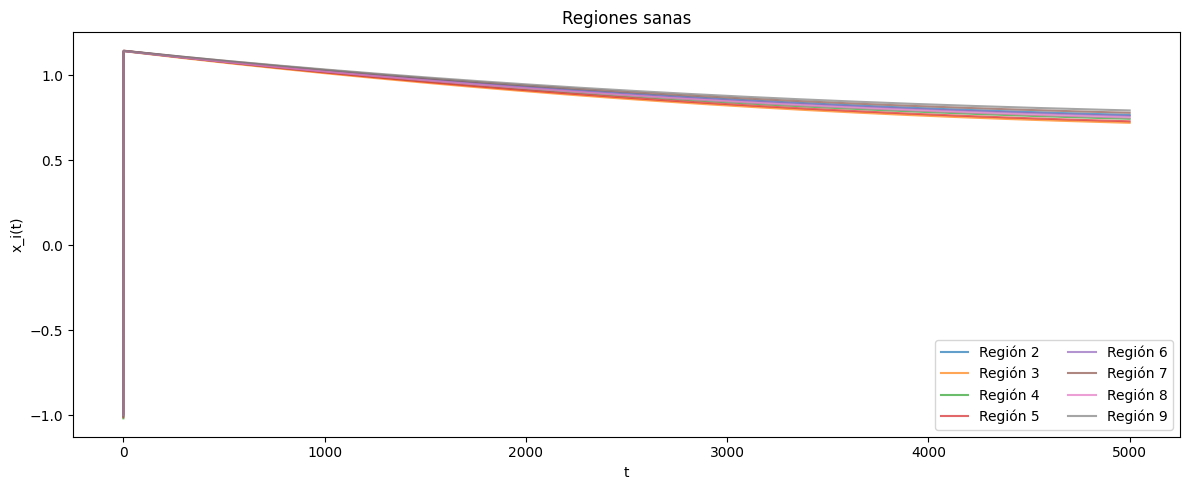

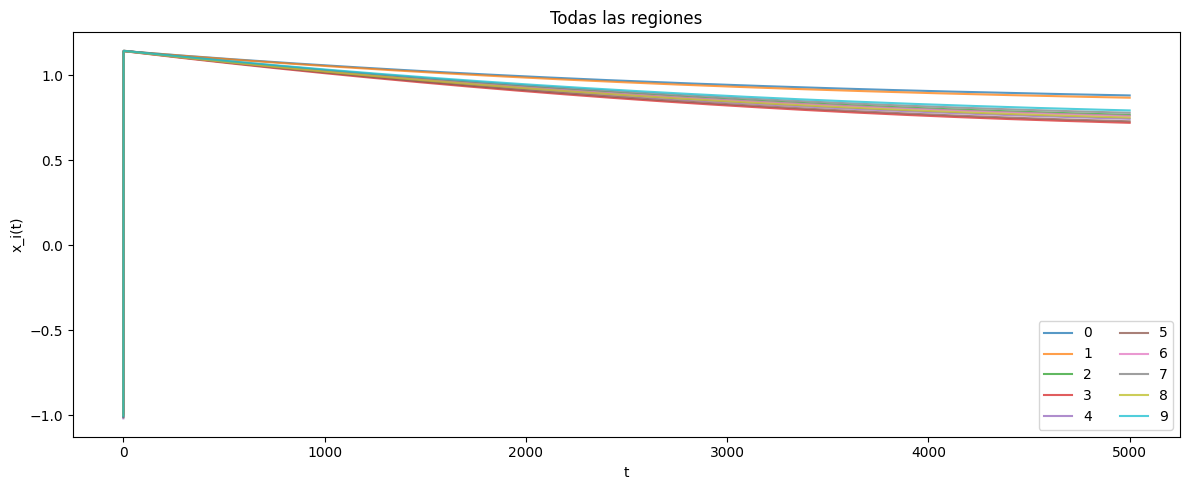

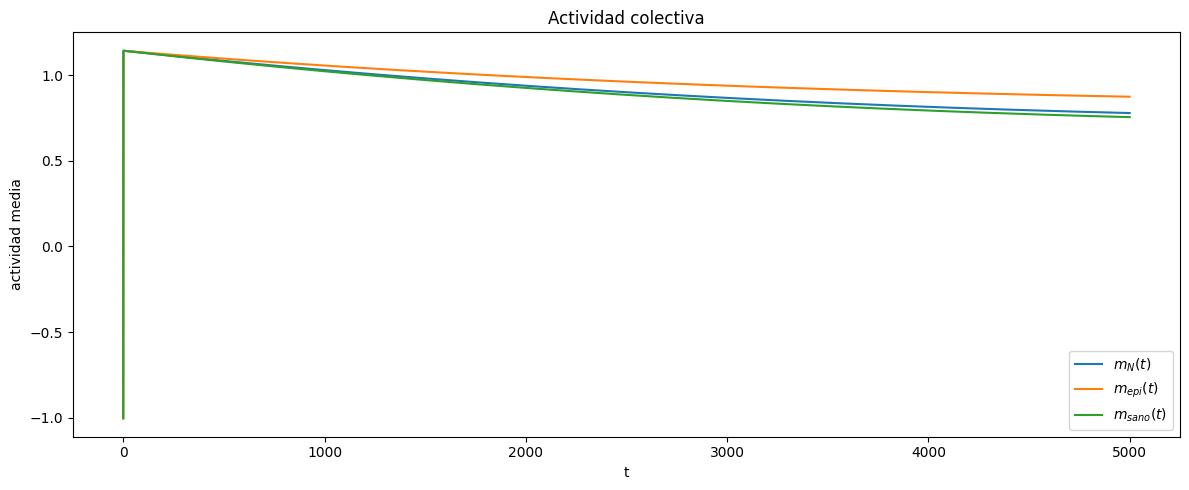

In [ ]:
def collective_observables(x):
    N = x.shape[0]
    m_N = x.mean(axis=0)
    m_epi = x[:2].mean(axis=0)
    m_sano = x[2:].mean(axis=0) if N > 2 else np.full(x.shape[1], np.nan)
    return m_N, m_epi, m_sano

def plot_time_series(t, x, x0, filename_prefix="series"):
    N = x.shape[0]

    fig1, ax1 = plt.subplots(figsize=(12, 5))
    for i in range(min(2, N)):
        ax1.plot(t, x[i], label=f"Región {i} (x₀={x0[i]:.2f})")
    ax1.set(xlabel="t", ylabel="x_i(t)", title="Regiones epileptogénicas")
    ax1.legend()
    fig1.tight_layout()
    fig1.savefig(FIG_DIR/f"{filename_prefix}_epi.png", dpi=200)
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(12, 5))
    for i in range(2, N):
        ax2.plot(t, x[i], alpha=0.7, label=f"Región {i}")
    ax2.set(xlabel="t", ylabel="x_i(t)", title="Regiones sanas")
    if N <= 15:
        ax2.legend(ncol=2)
    fig2.tight_layout()
    fig2.savefig(FIG_DIR/f"{filename_prefix}_sanas.png", dpi=200)
    plt.show()

    fig3, ax3 = plt.subplots(figsize=(12, 5))
    for i in range(N):
        ax3.plot(t, x[i], alpha=0.75, label=f"{i}")
    ax3.set(xlabel="t", ylabel="x_i(t)", title="Todas las regiones")
    if N <= 15:
        ax3.legend(ncol=2)
    fig3.tight_layout()
    fig3.savefig(FIG_DIR/f"{filename_prefix}_todas.png", dpi=200)
    plt.show()

def plot_collective_activity(t, x, filename="actividad_media.png"):
    m_N, m_epi, m_sano = collective_observables(x)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(t, m_N, label=r"$m_N(t)$")
    ax.plot(t, m_epi, label=r"$m_{epi}(t)$")
    ax.plot(t, m_sano, label=r"$m_{sano}(t)$")
    ax.set(xlabel="t", ylabel="actividad media", title="Actividad colectiva")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200)
    plt.show()

# Simulación base moderada; aumentar T para el estudio final.
BASE_K = 0.1
t, x, z, sol = simulate(
    x0, A, K=BASE_K,
    x_init=x_init_B, z_init=z_init_B,
    T=5000.0, n_samples=5000,
    method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
)

plot_time_series(t, x, x0)
plot_collective_activity(t, x)


# 10. Reclutamiento: definición operacional

Se define

\[
T_i=\inf\{t:x_i(t)>x_{\rm th}
\text{ durante al menos }\Delta t\}.
\]

Los parámetros \(x_{\rm th}\) y \(\Delta t\) deben fijarse **antes de interpretar los resultados** y luego someterse a análisis de sensibilidad.

La implementación siguiente busca el primer intervalo suficientemente largo por encima del umbral.


In [ ]:
def first_sustained_crossing(t, signal, threshold, min_duration):
    """Primer tiempo con señal > threshold durante al menos min_duration."""
    above = np.asarray(signal) > threshold
    if not np.any(above):
        return np.inf

    starts = np.where(above & ~np.r_[False, above[:-1]])[0]
    ends = np.where(~above & np.r_[False, above[:-1]])[0]

    if above[-1]:
        ends = np.r_[ends, len(above)]

    for s in starts:
        e_candidates = ends[ends > s]
        if len(e_candidates) == 0:
            continue
        e = e_candidates[0]
        if t[e-1] - t[s] >= min_duration:
            return float(t[s])

    return np.inf

def recruitment_times(t, x, threshold, min_duration):
    return np.array([
        first_sustained_crossing(t, x[i], threshold, min_duration)
        for i in range(x.shape[0])
    ])

X_THRESHOLD = 1.0
MIN_DURATION = 50.0

T_recruit = recruitment_times(t, x, X_THRESHOLD, MIN_DURATION)

order = np.argsort(T_recruit)
print("Secuencia de reclutamiento:")
for rank, i in enumerate(order, start=1):
    val = T_recruit[i]
    print(f"{rank:2d}. región {i}: T = {val if np.isfinite(val) else 'no reclutada'}")


Secuencia de reclutamiento:
 1. región 0: T = 1.0002000400080016
 2. región 1: T = 1.0002000400080016
 3. región 2: T = 1.0002000400080016
 4. región 3: T = 1.0002000400080016
 5. región 4: T = 1.0002000400080016
 6. región 5: T = 1.0002000400080016
 7. región 6: T = 1.0002000400080016
 8. región 7: T = 1.0002000400080016
 9. región 8: T = 1.0002000400080016
10. región 9: T = 1.0002000400080016


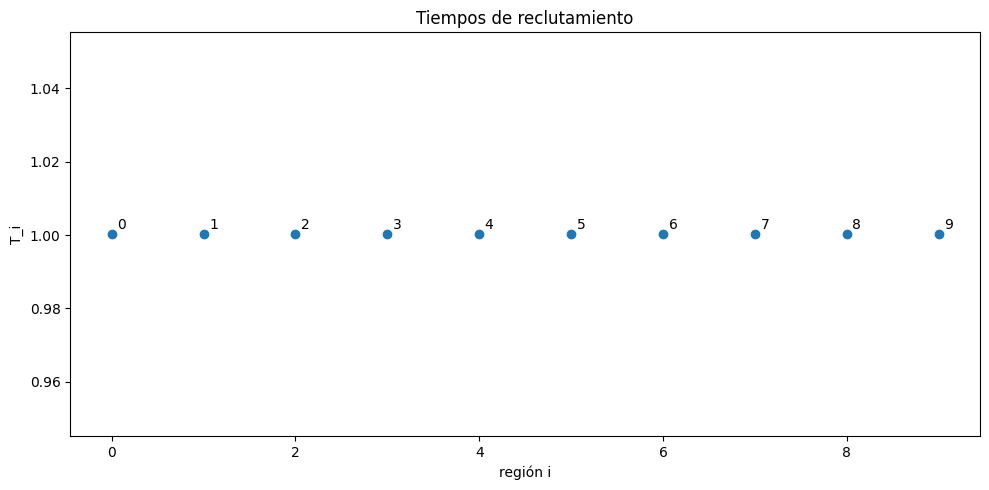

In [ ]:
def plot_recruitment_times(T_recruit, x0, filename="tiempos_reclutamiento.png"):
    fig, ax = plt.subplots(figsize=(10, 5))
    vals = np.where(np.isfinite(T_recruit), T_recruit, np.nan)
    ax.scatter(np.arange(len(vals)), vals)
    for i, Ti in enumerate(vals):
        if np.isfinite(Ti):
            ax.annotate(str(i), (i, Ti), xytext=(4, 4), textcoords="offset points")
    ax.set(xlabel="región i", ylabel="T_i", title="Tiempos de reclutamiento")
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200)
    plt.show()

plot_recruitment_times(T_recruit, x0)


# 11. Sensibilidad de \(x_{\rm th}\) y \(\Delta t\)

La elección del umbral no debe depender de una inspección posterior de la figura.

Se reporta cómo cambia el número de regiones reclutadas al variar ambos parámetros.


In [ ]:
def recruitment_fraction(T_recruit, N):
    healthy = np.arange(2, N)
    recruited = np.isfinite(T_recruit[healthy])
    return recruited.mean() if len(healthy) else np.nan

thresholds = [0.5, 0.75, 1.0, 1.25, 1.5]
durations = [10, 25, 50, 100]

rows = []
for th in thresholds:
    for dur in durations:
        Ti = recruitment_times(t, x, th, dur)
        rows.append({
            "threshold": th,
            "min_duration": dur,
            "R": recruitment_fraction(Ti, N)
        })

sensitivity_recruitment = pd.DataFrame(rows)
display(sensitivity_recruitment.pivot(index="threshold", columns="min_duration", values="R"))


min_duration,10,25,50,100
threshold,,,,
0.50,1.0,1.0,1.0,1.0
0.75,1.0,1.0,1.0,1.0
1.00,1.0,1.0,1.0,1.0
1.25,0.0,0.0,0.0,0.0
1.50,0.0,0.0,0.0,0.0


# 12. Mapa espacio-tiempo

Se construye

\[
X_{i,k}=x_i(t_k)
\]

y se visualiza mediante un heatmap. Esta es una de las figuras principales para identificar posibles patrones de propagación.


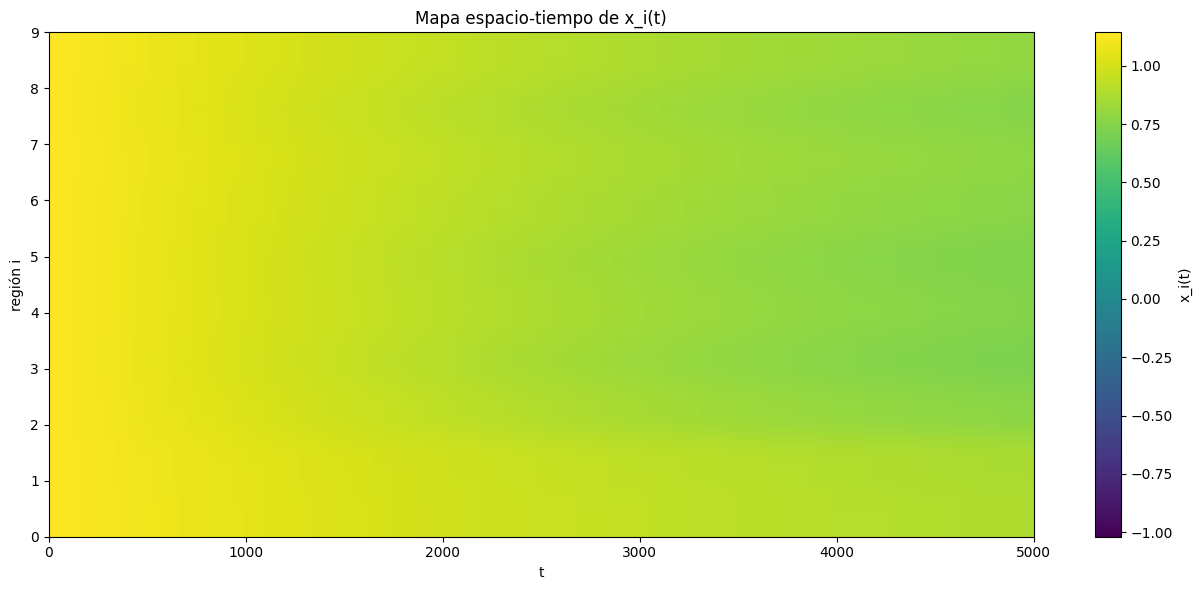

In [ ]:
def plot_spacetime(t, x, filename="mapa_espacio_tiempo.png"):
    fig, ax = plt.subplots(figsize=(13, 6))
    im = ax.imshow(
        x,
        aspect="auto",
        origin="lower",
        extent=[t[0], t[-1], 0, x.shape[0]-1]
    )
    ax.set(xlabel="t", ylabel="región i", title="Mapa espacio-tiempo de x_i(t)")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("x_i(t)")
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200)
    plt.show()

plot_spacetime(t, x)


# 13. Grafo dinámico

Se define la influencia instantánea absoluta

\[
W^{(1)}_{ij}(t)=K A_{ij}|x_j(t)-x_i(t)|.
\]

También se conserva la versión con signo:

\[
W^{(2)}_{ij}(t)=K A_{ij}(x_j(t)-x_i(t)).
\]

No son equivalentes:

- \(W^{(1)}\) mide intensidad absoluta;
- \(W^{(2)}\) conserva dirección/signo de la diferencia de actividad.

La primera puede interpretarse como una **medida instantánea de intensidad de interacción del término de acoplamiento**, no como una medida causal.


In [ ]:
def dynamic_weight_matrices(x, A, K):
    """Devuelve W_abs[t,i,j] y W_signed[t,i,j]."""
    A = np.asarray(A)
    diff = x[:, None, :] - x[None, :, :]  # [i,j,t] = x_j - x_i
    W_abs = K * A[:, :, None] * np.abs(diff)
    W_signed = K * A[:, :, None] * diff
    return np.moveaxis(W_abs, 2, 0), np.moveaxis(W_signed, 2, 0)

W_abs, W_signed = dynamic_weight_matrices(x, A, BASE_K)

print("Shape W_abs:", W_abs.shape, " = (tiempo, i, j)")


Shape W_abs: (5000, 10, 10)  = (tiempo, i, j)


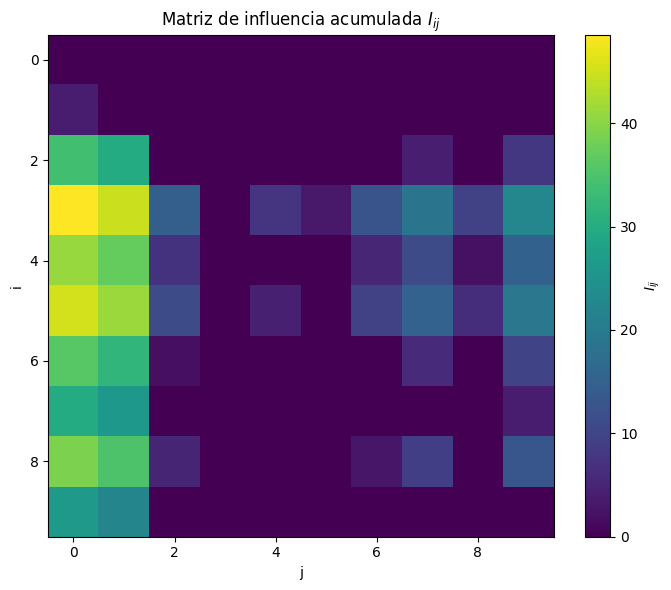

I_dyn =
[[ 0.      0.      0.      0.      0.      0.      0.      0.      0.
   0.    ]
 [ 3.9758  0.      0.      0.      0.      0.      0.      0.      0.
   0.    ]
 [33.9373 29.9629  0.      0.      0.      0.      0.      4.0373  0.
   7.9266]
 [48.5706 44.5965 14.6359  0.      7.4815  3.3173 12.6662 18.6733  9.6393
  22.5625]
 [41.0918 37.1162  7.1571  0.      0.      0.      5.1868 11.1934  2.1699
  15.0821]
 [45.264  41.2883 11.331   0.      4.2158  0.      9.3719 15.357   6.3828
  19.2504]
 [35.9056 31.931   1.9704  0.      0.      0.      0.      6.0071  0.
   9.8963]
 [29.913  25.9388  0.      0.      0.      0.      0.      0.      0.
   3.9162]
 [38.9316 34.9571  4.9974  0.      0.      0.      3.027   9.034   0.
  12.9232]
 [26.0137 22.0381  0.      0.      0.      0.      0.      0.      0.
   0.    ]]


In [ ]:
def cumulative_influence(t, W):
    """Integral temporal por trapecios: I_ij = integral W_ij(t) dt."""
    return np.trapezoid(W, x=t, axis=0)

I_dyn = cumulative_influence(t, W_abs)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(I_dyn, origin="upper", aspect="auto")
ax.set(xlabel="j", ylabel="i", title=r"Matriz de influencia acumulada $I_{ij}$")
fig.colorbar(im, ax=ax, label=r"$I_{ij}$")
fig.tight_layout()
fig.savefig(FIG_DIR/"influencia_acumulada.png", dpi=200)
plt.show()

print("I_dyn =")
print(I_dyn)


# 14. Grafo dinámico en distintos tiempos

Se representa \(W_{ij}(t)\) como peso de las aristas.

Para evitar llenar la figura con aristas insignificantes, se puede usar un percentil configurable como umbral visual. Esto es únicamente una decisión de visualización y no modifica \(W(t)\).


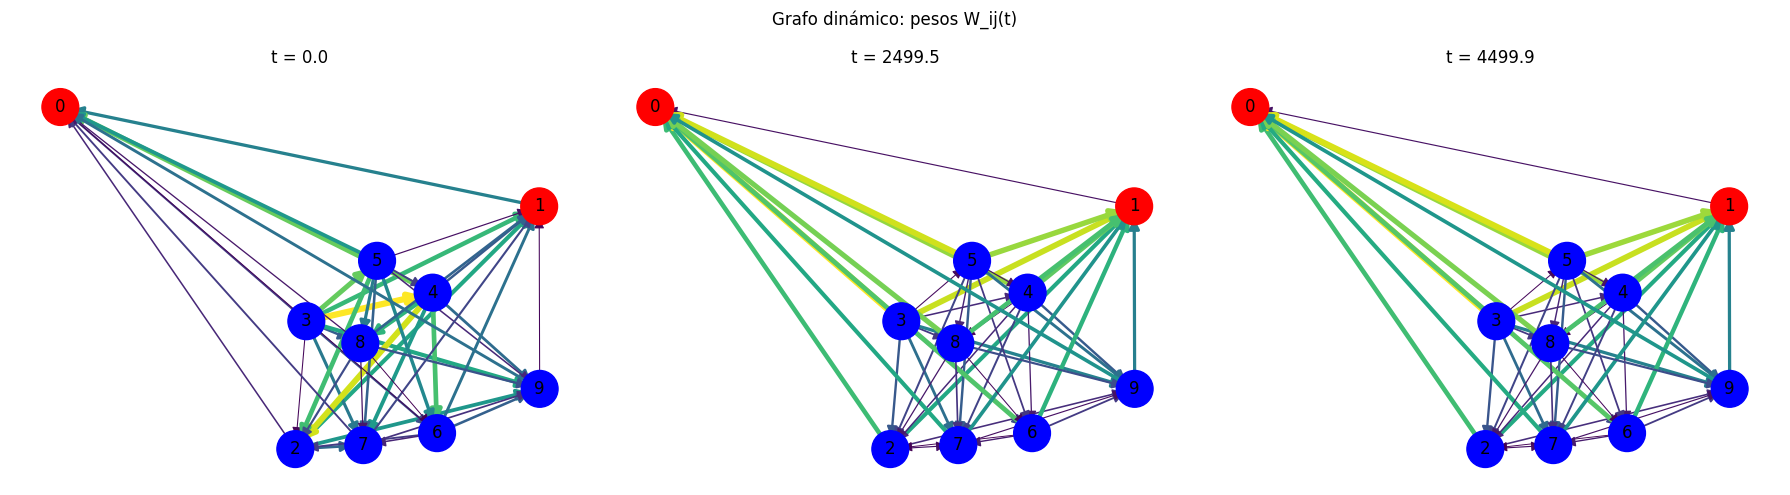

In [ ]:
def plot_dynamic_graph(A, x, t, W_abs, times=(0, 0.5, 0.9),
                          filename="grafo_dinamico.png"):
    G = build_graph(A)
    pos = nx.spring_layout(G, seed=42)

    indices = [min(int(frac*(len(t)-1)), len(t)-1) for frac in times]

    fig, axes = plt.subplots(1, len(indices), figsize=(6*len(indices), 5))
    if len(indices) == 1:
        axes = [axes]

    for ax, k in zip(axes, indices):
        weights = W_abs[k]
        edges = list(G.edges())

        if edges:
            vals = np.array([weights[u, v] for u, v in edges])
            vmax = vals.max() if vals.max() > 0 else 1.0
            widths = 0.5 + 4.0 * vals / vmax
        else:
            widths = []

        nx.draw_networkx_nodes(
            G, pos, ax=ax,
            node_color=['red' if xi < X0_REFERENCE else 'blue' for xi in x0],
            node_size=700
        )
        nx.draw_networkx_labels(G, pos, ax=ax)
        if edges:
            nx.draw_networkx_edges(
                G, pos, ax=ax, edgelist=edges,
                width=widths, arrows=True, arrowsize=15,
                edge_color=vals
            )
        ax.set_title(f"t = {t[k]:.1f}")
        ax.axis("off")

    fig.suptitle("Grafo dinámico: pesos W_ij(t)")
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200, bbox_inches="tight")
    plt.show()

plot_dynamic_graph(A, x, t, W_abs)


# 15. Hubs dinámicos y comparación con estructura

Se define

\[
H_i^{dyn,out}=\sum_j I_{ij},
\qquad
H_i^{dyn,in}=\sum_j I_{ji}.
\]

Se comparan con

\[
d_i^{out},\quad d_i^{in},\quad C_B(i).
\]

Una correlación alta no implica causalidad.


In [ ]:
H_dyn_out = I_dyn.sum(axis=1)
H_dyn_in = I_dyn.sum(axis=0)

analysis_df = topology.copy()
analysis_df["H_dyn_out"] = H_dyn_out
analysis_df["H_dyn_in"] = H_dyn_in
analysis_df["T_recruit"] = T_recruit
analysis_df["x0"] = x0
analysis_df["epileptogenic_label"] = x0 < X0_REFERENCE

display(analysis_df)

def safe_corr(x, y, method="pearson"):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 3 or np.std(x[mask]) == 0 or np.std(y[mask]) == 0:
        return np.nan, np.nan
    if method == "spearman":
        return spearmanr(x[mask], y[mask])
    return pearsonr(x[mask], y[mask])

print("corr(out_degree, H_dyn_out):", safe_corr(analysis_df.out_degree, analysis_df.H_dyn_out))
print("corr(betweenness, H_dyn_out):", safe_corr(analysis_df.betweenness, analysis_df.H_dyn_out))


,out_degree,in_degree,betweenness,clustering,scc_id,H_dyn_out,H_dyn_in,T_recruit,x0,epileptogenic_label
node,,,,,,,,,,
0,0,9,0.0,0.5,0,0.000000,303.603559,1.0002,2.300000,True
1,1,8,0.0,0.5,1,3.975834,267.828842,1.0002,2.400000,True
2,4,5,0.0,0.5,4,75.864110,40.091899,1.0002,3.122479,False
3,9,0,0.0,0.5,9,182.143115,0.000000,1.0002,3.456059,False
4,7,2,0.0,0.5,7,118.997287,11.697294,1.0002,3.286319,False
5,8,1,0.0,0.5,8,152.461261,3.317262,1.0002,3.393657,False
6,5,4,0.0,0.5,5,85.710297,30.251917,1.0002,3.166049,False
7,3,6,0.0,0.5,3,59.767990,64.302096,1.0002,3.036343,False
8,6,3,0.0,0.5,6,103.870417,18.191959,1.0002,3.232751,False


corr(out_degree, H_dyn_out): PearsonRResult(statistic=np.float64(0.9874694439721988), pvalue=np.float64(1.0624635606670946e-07))
corr(betweenness, H_dyn_out): (nan, nan)


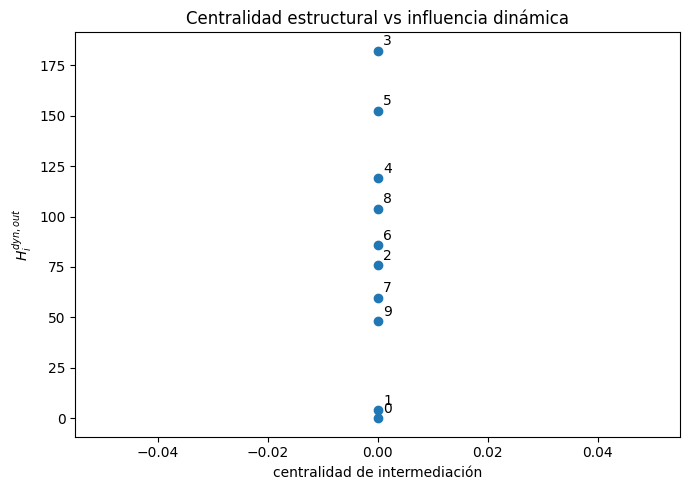

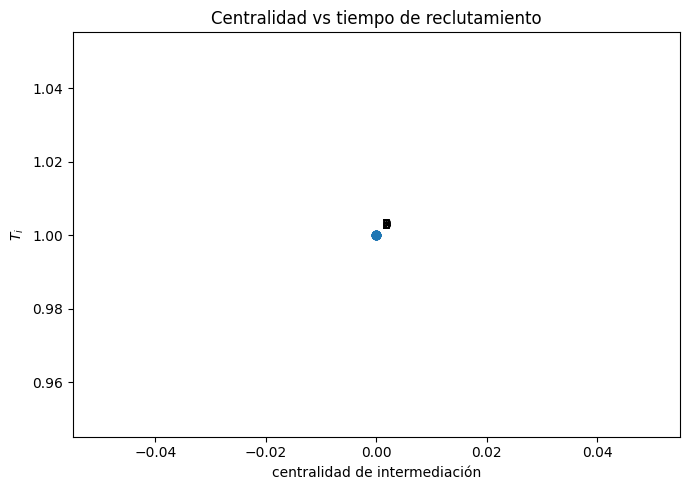

corr(betweenness, T_recruit): (nan, nan)


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(analysis_df["betweenness"], analysis_df["H_dyn_out"])
for i, row in analysis_df.iterrows():
    ax.annotate(str(i), (row["betweenness"], row["H_dyn_out"]), xytext=(4,4),
                textcoords="offset points")
ax.set(xlabel="centralidad de intermediación", ylabel=r"$H_i^{dyn,out}$",
       title="Centralidad estructural vs influencia dinámica")
fig.tight_layout()
fig.savefig(FIG_DIR/"centralidad_vs_influencia.png", dpi=200)
plt.show()

mask = np.isfinite(analysis_df["T_recruit"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(analysis_df.loc[mask, "betweenness"],
           analysis_df.loc[mask, "T_recruit"])
for i in analysis_df.index[mask]:
    ax.annotate(str(i),
                (analysis_df.loc[i, "betweenness"], analysis_df.loc[i, "T_recruit"]),
                xytext=(4,4), textcoords="offset points")
ax.set(xlabel="centralidad de intermediación", ylabel=r"$T_i$",
       title="Centralidad vs tiempo de reclutamiento")
fig.tight_layout()
fig.savefig(FIG_DIR/"centralidad_vs_reclutamiento.png", dpi=200)
plt.show()

print("corr(betweenness, T_recruit):",
      safe_corr(analysis_df.betweenness.values, analysis_df.T_recruit.values))


# 16. Perturbación dinámica

Para una región \(i\), se compara el sistema original con una modificación de su estado inicial.

Se define

\[
D_i=\int_0^T\|X^{(i)}(t)-X(t)\|\,dt.
\]

Esta cantidad se interpreta como **sensibilidad dinámica a la perturbación elegida**. No debe interpretarse automáticamente como causalidad fisiológica.


In [ ]:
def perturbation_impact(
    x0, A, K, base_x, base_z,
    node, delta_x=0.05, T=5000.0, n_samples=3000,
    method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
):
    t1, x1, z1, sol1 = simulate(
        x0, A, K, base_x, base_z, T, n_samples,
        method, rtol, atol, max_step
    )

    pert_x = np.array(base_x, copy=True)
    pert_x[node] += delta_x

    t2, x2, z2, sol2 = simulate(
        x0, A, K, pert_x, base_z, T, n_samples,
        method, rtol, atol, max_step
    )

    X1 = np.vstack([x1, z1])
    X2 = np.vstack([x2, z2])
    distance = np.linalg.norm(X2 - X1, axis=0)
    D = np.trapezoid(distance, x=t1)

    return D, t1, distance

# Para un estudio completo, repetir para todos los nodos.
# Aquí se deja un ejemplo.
D_example, _, _ = perturbation_impact(
    x0, A, BASE_K, x_init_B, z_init_B, node=0, T=2000, n_samples=1500
)
print("D_0 =", D_example)


D_0 = 0.0581492473775406


# 17. Control de acoplamiento: \(A=0\) y \(K>0\)

Se compara:

\[
K=0
\]

con

\[
K>0.
\]

También se puede usar directamente \(A=0\). El objetivo es verificar que el reclutamiento adicional realmente depende del acoplamiento de red y no solamente de la dinámica individual.


In [ ]:
def run_recruitment_experiment(A_use, K, T=5000.0, n_samples=5000,
                                 threshold=X_THRESHOLD, min_duration=MIN_DURATION,
                                 seed=SEED):
    xi, zi = initial_conditions(len(x0), "B", seed)
    tt, xx, zz, ss = simulate(
        x0, A_use, K, xi, zi,
        T=T, n_samples=n_samples,
        method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
    )
    Ti = recruitment_times(tt, xx, threshold, min_duration)
    return {
        "t": tt, "x": xx, "z": zz, "T": Ti,
        "R": recruitment_fraction(Ti, len(x0))
    }

control_K0 = run_recruitment_experiment(A, K=0.0, T=3000, n_samples=3000)
coupled = run_recruitment_experiment(A, K=BASE_K, T=3000, n_samples=3000)

print("R(K=0) =", control_K0["R"])
print("R(K>0) =", coupled["R"])


R(K=0) = 1.0
R(K>0) = 1.0


# 18. Control de dirección: \(A\) vs \(A^T\)

Se repite el experimento con ambas orientaciones.

Se comparan:

- número/fracción de regiones reclutadas;
- tiempos \(T_i\);
- actividad colectiva;
- influencia acumulada;
- hubs dinámicos.

La diferencia entre ambos experimentos cuantifica cuánto depende el fenómeno de la convención de dirección.


In [ ]:
def compare_directions(K=BASE_K, T=3000.0, n_samples=3000):
    results = {}
    for name, A_use in [("A", A), ("A_T", A.T)]:
        xi, zi = initial_conditions(N, "B", SEED)
        tt, xx, zz, ss = simulate(
            x0, A_use, K, xi, zi,
            T=T, n_samples=n_samples,
            method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
        )
        Ti = recruitment_times(tt, xx, X_THRESHOLD, MIN_DURATION)
        W, _ = dynamic_weight_matrices(xx, A_use, K)
        Icum = cumulative_influence(tt, W)
        results[name] = {
            "t": tt, "x": xx, "z": zz,
            "T": Ti, "R": recruitment_fraction(Ti, N),
            "I": Icum,
            "H_out": Icum.sum(axis=1),
            "H_in": Icum.sum(axis=0)
        }
    return results

direction_results = compare_directions()
print("R(A)   =", direction_results["A"]["R"])
print("R(A^T) =", direction_results["A_T"]["R"])


R(A)   = 1.0
R(A^T) = 1.0


# 19. Estudio del acoplamiento \(K\)

Se define

\[
R(K)=
\frac{\#\{\text{regiones sanas reclutadas}\}}{N-2},
\qquad 0\le R(K)\le1.
\]

Se explora

\[
K\in\{0,K_1,\ldots,K_{\max}\}.
\]

No se declara un \(K_c\) sin observar la transición y comprobar su robustez.


,K,n_recruited_healthy,R
0,0.00,8,1.0
1,0.02,8,1.0
2,0.05,8,1.0
3,0.10,8,1.0
4,0.20,8,1.0
5,0.50,8,1.0


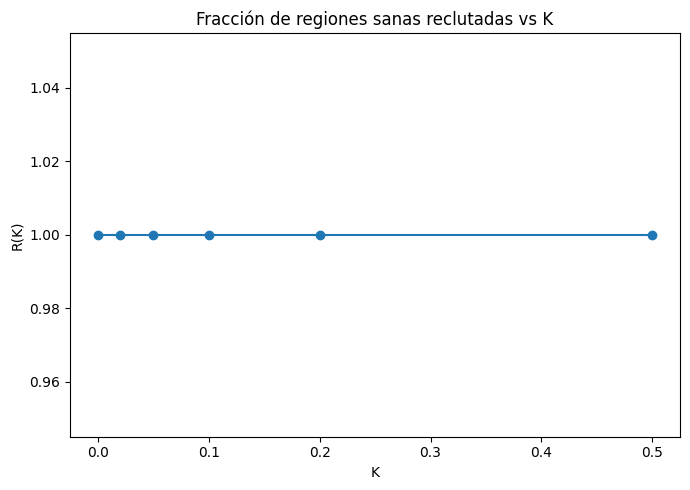

In [ ]:
def sweep_K(K_values, T=3000.0, n_samples=3000, seed=SEED):
    rows = []
    for K in K_values:
        result = run_recruitment_experiment(
            A, K, T=T, n_samples=n_samples, seed=seed
        )
        Ti = result["T"]
        healthy = np.arange(2, N)
        n_recruited = np.isfinite(Ti[healthy]).sum()
        rows.append({
            "K": K,
            "n_recruited_healthy": int(n_recruited),
            "R": n_recruited / max(1, len(healthy))
        })
    return pd.DataFrame(rows)

# Barrido moderado; aumentar resolución para el estudio final.
K_VALUES = np.array([0.0, 0.02, 0.05, 0.1, 0.2, 0.5])
K_results = sweep_K(K_VALUES, T=2000, n_samples=2000)
display(K_results)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(K_results["K"], K_results["R"], marker="o")
ax.set(xlabel="K", ylabel="R(K)", title="Fracción de regiones sanas reclutadas vs K")
fig.tight_layout()
fig.savefig(FIG_DIR/"reclutamiento_vs_K.png", dpi=200)
plt.show()


# 20. Escalamiento con \(N\)

El estudio solicitado considera, según capacidad computacional,

\[
N=2,5,10,20,50,100,200,\ldots
\]

Para cada \(N\) se debe generar \(x_0\), construir \(A\), calcular métricas, simular, obtener \(T_i\), \(W(t)\), hubs y \(R(K)\).

**Advertencia:** el código de esta sección puede ser costoso para \(N\) grande. Para \(N\gg1\), la matriz \(A\) y el almacenamiento de \(W(t)\) pueden convertirse en el cuello de botella.


In [ ]:
def one_N_experiment(N_value, K=BASE_K, seed=SEED,
                      T=2000.0, n_samples=1500,
                      normalized=False):
    x0_N = generate_x0(N_value, seed)
    A_N = build_adjacency(x0_N)

    K_eff = K / N_value if normalized else K
    xi, zi = initial_conditions(N_value, "B", seed)

    tt, xx, zz, ss = simulate(
        x0_N, A_N, K_eff, xi, zi,
        T=T, n_samples=n_samples,
        method="DOP853", rtol=1e-7, atol=1e-9, max_step=20.0
    )

    Ti = recruitment_times(tt, xx, X_THRESHOLD, MIN_DURATION)
    healthy = np.arange(2, N_value)
    R = np.isfinite(Ti[healthy]).mean() if len(healthy) else np.nan

    return {
        "N": N_value,
        "seed": seed,
        "R": R,
        "mean_T_healthy": np.nanmean(
            np.where(np.isfinite(Ti[healthy]), Ti[healthy], np.nan)
        ) if len(healthy) else np.nan,
        "n_edges": int(A_N.sum()),
        "K_effective": K_eff
    }

# Ejemplo pequeño
N_scaling_example = [2, 5, 10]
scaling_rows = [
    one_N_experiment(nv, K=BASE_K, seed=SEED, T=1000, n_samples=1000)
    for nv in N_scaling_example
]
scaling_df = pd.DataFrame(scaling_rows)
display(scaling_df)


,N,seed,R,mean_T_healthy,n_edges,K_effective
0,2,42,NaN,NaN,1,0.1
1,5,42,1.0,1.001001,10,0.1
2,10,42,1.0,1.001001,45,0.1


# 21. Acoplamiento normalizado vs no normalizado

Se comparan:

### No normalizado

\[
K\sum_jA_{ij}(x_j-x_i).
\]

### Normalizado

\[
\frac{\kappa}{N}\sum_jA_{ij}(x_j-x_i).
\]

No se asume que ambos modelos tengan el mismo límite cuando \(N\to\infty\).


In [ ]:
def compare_normalization(N_values=(5, 10, 20), kappa=BASE_K,
                           T=1000.0, n_samples=800):
    rows = []
    for nv in N_values:
        for normalized in [False, True]:
            out = one_N_experiment(
                nv, K=kappa, seed=SEED,
                T=T, n_samples=n_samples,
                normalized=normalized
            )
            out["normalized"] = normalized
            rows.append(out)
    return pd.DataFrame(rows)

normalization_df = compare_normalization()
display(normalization_df)


,N,seed,R,mean_T_healthy,n_edges,K_effective,normalized
0,5,42,1.0,1.251564,10,0.100,False
1,5,42,1.0,1.251564,10,0.020,True
2,10,42,1.0,1.251564,45,0.100,False
3,10,42,1.0,1.251564,45,0.010,True
4,20,42,1.0,1.251564,190,0.100,False
5,20,42,1.0,1.251564,190,0.005,True


# 22. Comparación con campo medio

El modelo de campo medio considerado es

\[
\dot z_i=
\frac1{\tau_0}
[h_i(x_i)-z_i-\kappa(m_N-x_i)].
\]

El modelo de red es

\[
\dot z_i=
\frac1{\tau_0}
\left[
h_i(x_i)-z_i-K\sum_jA_{ij}(x_j-x_i)
\right].
\]

Para comparar ambos términos, calculamos el acoplamiento real de red y una aproximación de campo medio.

La pregunta no es si son idénticos, sino **en qué régimen la interacción de red puede aproximarse por una interacción media**.


In [ ]:
def coupling_network(x, A, K):
    return K * np.sum(A[None, :, :] * (x[:, None, :] - x[None, :, :]), axis=1)

def coupling_mean_field(x, kappa):
    m = x.mean(axis=0)
    return kappa * (m[None, :] - x)

network_coupling = coupling_network(x, A, BASE_K)
meanfield_coupling = coupling_mean_field(x, BASE_K)

relative_error_mf = (
    np.linalg.norm(network_coupling - meanfield_coupling)
    / max(np.linalg.norm(network_coupling), 1e-14)
)

print("Error relativo global red vs campo medio:", relative_error_mf)


ValueError: operands could not be broadcast together with shapes (1,10,10) (10,10,5000) 

# 23. Experimentos estadísticos

Una sola realización no basta para una conclusión estadística.

La propuesta es usar

\[
M=30\text{ o }50
\]

semillas para cada configuración \((N,K,\operatorname{Var}(x_0))\), y reportar:

\[
\mathbb E[R(K)],\qquad \operatorname{Std}(R(K)),
\]

además de medias y desviaciones de los tiempos de reclutamiento.

Por defecto se usa un número pequeño de réplicas para probar el pipeline.


In [ ]:
def statistical_replicates(
    N_value=10, K=BASE_K, M=5,
    T=1500.0, n_samples=1000,
    normalized=False, seed0=1000
):
    rows = []
    for r in range(M):
        seed = seed0 + r
        out = one_N_experiment(
            N_value, K=K, seed=seed,
            T=T, n_samples=n_samples,
            normalized=normalized
        )
        out["replicate"] = r
        rows.append(out)

    df = pd.DataFrame(rows)
    summary = df.agg({
        "R": ["mean", "std"],
        "mean_T_healthy": ["mean", "std"]
    })
    return df, summary

replicates_df, replicates_summary = statistical_replicates(M=3)
display(replicates_df)
display(replicates_summary)


# 24. Validación de convergencia temporal

Se comparan diferentes configuraciones de `rtol`, `atol` y `max_step`.

La idea es verificar que las cantidades de interés —por ejemplo \(R(K)\), \(T_i\) y \(m_N(t)\)— no cambien significativamente al refinar la integración.


In [ ]:
def convergence_study(
    x0, A, K, x_init, z_init,
    configs, T=1500.0, n_samples=1200
):
    rows = []
    trajectories = {}

    for cfg in configs:
        key = str(cfg)
        tt, xx, zz, sol = simulate(
            x0, A, K, x_init, z_init,
            T=T, n_samples=n_samples,
            method=cfg.get("method", "DOP853"),
            rtol=cfg.get("rtol", 1e-8),
            atol=cfg.get("atol", 1e-10),
            max_step=cfg.get("max_step", np.inf)
        )
        Ti = recruitment_times(tt, xx, X_THRESHOLD, MIN_DURATION)

        rows.append({
            "config": key,
            "method": cfg.get("method", "DOP853"),
            "rtol": cfg.get("rtol", 1e-8),
            "atol": cfg.get("atol", 1e-10),
            "max_step": cfg.get("max_step", np.inf),
            "R": recruitment_fraction(Ti, len(x0)),
            "nfev": sol.nfev
        })
        trajectories[key] = (tt, xx)

    return pd.DataFrame(rows), trajectories

configs = [
    {"method": "DOP853", "rtol": 1e-6, "atol": 1e-8, "max_step": 50},
    {"method": "DOP853", "rtol": 1e-8, "atol": 1e-10, "max_step": 20},
    {"method": "DOP853", "rtol": 1e-10, "atol": 1e-12, "max_step": 10},
]

conv_df, conv_traj = convergence_study(
    x0, A, BASE_K, x_init_B, z_init_B, configs
)
display(conv_df)


# 25. Falsación de hipótesis

El análisis debe buscar activamente contraejemplos:

- ausencia de reclutamiento;
- una región sana reclutada antes que una epileptogénica;
- hub estructural que no sea hub dinámico;
- nodo de baja centralidad con gran influencia;
- diferencias grandes entre \(A\) e \(I\);
- cambios drásticos con \(N\);
- fracaso de \(N=2\) como representación de \(N\gg1\).

Una simulación que contradiga la hipótesis es un resultado relevante, no un error que deba eliminarse.


In [ ]:
def falsification_report(x0, topology, T_recruit, H_dyn_out, X0_REFERENCE=2.91):
    N = len(x0)
    epi = np.where(x0 < X0_REFERENCE)[0]
    healthy = np.where(x0 >= X0_REFERENCE)[0]

    first_epi = np.nanmin(np.where(np.isfinite(T_recruit[epi]), T_recruit[epi], np.nan))
    first_healthy = np.nanmin(np.where(np.isfinite(T_recruit[healthy]), T_recruit[healthy], np.nan))

    report = {
        "any_healthy_recruited": bool(np.any(np.isfinite(T_recruit[healthy]))),
        "healthy_before_epi": bool(
            np.isfinite(first_healthy) and
            np.isfinite(first_epi) and
            first_healthy < first_epi
        ),
        "first_epi_time": first_epi,
        "first_healthy_time": first_healthy,
        "structural_dynamic_corr": safe_corr(
            topology["betweenness"].values, H_dyn_out
        )[0]
    }
    return report

falsification = falsification_report(x0, topology, T_recruit, H_dyn_out)
falsification


# 26. Resumen automático de un experimento

Esta celda produce una tabla compacta de los principales resultados de la realización actual.


In [ ]:
summary = pd.DataFrame({
    "quantity": [
        "N",
        "seed",
        "K",
        "tau0",
        "I",
        "x0_reference",
        "edges",
        "R(K)",
        "mean H_dyn_out",
        "corr(betweenness, H_dyn_out)",
        "corr(betweenness, T_i)"
    ],
    "value": [
        N,
        SEED,
        BASE_K,
        TAU0,
        I_DEFAULT,
        X0_REFERENCE,
        int(A.sum()),
        recruitment_fraction(T_recruit, N),
        np.mean(H_dyn_out),
        safe_corr(topology["betweenness"], H_dyn_out)[0],
        safe_corr(topology["betweenness"], T_recruit)[0]
    ]
})
display(summary)
summary.to_csv(RES_DIR/"summary_experimento.csv", index=False)


# 27. Exportación de resultados

Se guardan los principales objetos numéricos para reproducibilidad:

- `x0`;
- `A`;
- `T_recruit`;
- `I_dyn`;
- métricas topológicas;
- resumen experimental.

La semilla utilizada también se registra.


In [ ]:
np.save(RES_DIR/"x0.npy", x0)
np.save(RES_DIR/"A.npy", A)
np.save(RES_DIR/"T_recruit.npy", T_recruit)
np.save(RES_DIR/"I_dynamic.npy", I_dyn)

topology.to_csv(RES_DIR/"topology_metrics.csv")
analysis_df.to_csv(RES_DIR/"node_analysis.csv")

with open(RES_DIR/"seed.txt", "w", encoding="utf-8") as f:
    f.write(str(SEED))

print("Resultados guardados en:", RES_DIR.resolve())
print("Figuras guardadas en:", FIG_DIR.resolve())


# 28. Lista de preguntas científicas finales

El estudio debe terminar evaluando explícitamente:

1. **¿Las regiones epileptogénicas reclutan a las sanas?**
2. **¿Existe una secuencia temporal de propagación?**
3. **¿Los hubs estructurales son hubs dinámicos?**
4. **¿La centralidad predice el tiempo de reclutamiento?**
5. **¿La propagación depende de la dirección del grafo?**
6. **¿Existe un umbral de acoplamiento \(K_c\)?**
7. **¿Cómo cambia el fenómeno con \(N\)?**
8. **¿Puede el campo medio reproducir el comportamiento de la red?**
9. **¿En qué sentido \(N=2\) puede representar \(N\gg1\)?**
10. **¿En qué situaciones falla esa aproximación?**

## Criterio de conclusión

Separar siempre:

\[
\boxed{\text{resultado analítico}},\qquad
\boxed{\text{resultado numérico}},\qquad
\boxed{\text{evidencia estadística}},\qquad
\boxed{\text{conjetura}}.
\]

No escribir «se demostró que...» cuando solo existen simulaciones. Usar, según corresponda:

- «La evidencia numérica es consistente con...»
- «El experimento proporciona un contraejemplo a...»
- «Los resultados sugieren que...»

La pregunta central es:

\[
\boxed{
\text{¿Puede la combinación de }x_{0,i}\text{ y }A
\text{ explicar cuantitativamente la propagación y cómo cambia con }N?
}
\]


# 29. Nota sobre ejecución a gran escala

Para el estudio definitivo se recomienda separar el notebook en:

- **pipeline exploratorio:** \(N=10\), pocas semillas y tiempos moderados;
- **experimentos finales:** múltiples semillas, convergencia numérica y sensibilidad;
- **escalamiento:** \(N=2,5,10,20,50,100,\ldots\), ajustando memoria y tiempo.

En particular, almacenar todo \(W_{ij}(t)\) tiene costo \(O(n_tN^2)\). Para redes grandes conviene calcular integrales y métricas por bloques o durante la integración, en vez de guardar toda la matriz temporal.

Asimismo, la construcción \(A=A(x_0)\) debe mantenerse identificada como una **hipótesis de modelamiento**, no como una inferencia de conectividad cerebral real.
